In [2]:
import sys
from pathlib import Path

# Add parent directory to path for imports
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import laspy
import numpy as np
import pandas as pd
from pyntcloud import PyntCloud
import matplotlib.pyplot as plt

print(f"✅ Project root: {PROJECT_ROOT}")
print(f"✅ All imports successful")

✅ Project root: /home/nvidia/projects/fvc_structure/phase_5_3d_cnn_training
✅ All imports successful


In [5]:
# Input directory containing LAS files with structure + treeID
INPUT_DIR = Path("/data/calperumResearch/site1_1_DD0001/lidar/clipped/3d_structure_mask_malleid")

# Output director
INPUT_PLY_DIR = Path("/data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/forestformer3d_ply/")
OUTPUT_NPY_DIR = Path("/data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/forestformer3d_npy/")


INPUT_PLY_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_NPY_DIR.mkdir(parents=True, exist_ok=True)

In [4]:
import datetime
import os
import sys
from os import path as osp

# Add forestformer_preprocessing to path
sys.path.insert(0, str(PROJECT_ROOT / "forestformer_preprocessing"))

# Create plyutils module inline since it's not in the repo
import importlib.util
spec = importlib.util.spec_from_loader("plyutils", loader=None)
plyutils = importlib.util.module_from_spec(spec)

def read_ply(filename):
    """Read PLY file using PyntCloud"""
    cloud = PyntCloud.from_file(str(filename))
    points_df = cloud.points
    
    # Print format information
    print(f"  PLY columns: {list(points_df.columns)}")
    print(f"  PLY shape: {points_df.shape}")
    
    # Convert to dictionary format expected by load_forainetv2_data
    result = {}
    for col in points_df.columns:
        result[col] = points_df[col].values
    return result

plyutils.read_ply = read_ply
sys.modules['plyutils'] = plyutils

# Now import the export function from load_forainetv2_data
from load_forainetv2_data import export

DONOTCARE_CLASS_IDS = np.array([])
FORAINETV2_OBJ_CLASS_IDS = np.array([1])


def guess_original_las(stem: str):
    """Heuristic to map processed scan names back to original LAS filenames."""
    variants = set()
    variants.add(stem)
    variants.add(stem.replace("_from_ply", ""))
    variants.add(stem.replace("_from_npz", ""))
    variants.add(stem.replace("_knnclustering", ""))
    variants.add(stem.replace("_forest", ""))
    for variant in variants:
        variant = variant.strip()
        if not variant:
            continue
        candidate = INPUT_DIR / f"{variant}.las"
        if candidate.exists():
            return candidate
    return None


def export_one_scan_forestformer(scan_name, output_filename_prefix, max_num_point, 
                                  ply_dir, test_mode=False):
    """
    Export one PLY scan to NPZ format using ForestFormer's export function.
    
    IMPORTANT: Combines preprocessing offset (LAS→PLY) with ForestFormer recentering offset 
    to enable full reconstruction back to original LAS global coordinates.
    """
    ply_file = osp.join(ply_dir, scan_name + '.ply')
    
    # Read original LAS file to get CRS and header information
    original_las_path = guess_original_las(scan_name)
    crs_info = None
    original_las = None
    if original_las_path is not None:
        try:
            original_las = laspy.read(str(original_las_path))
            header_offsets = np.array(original_las.header.offsets, dtype=np.float64)
            header_scales = np.array(original_las.header.scales, dtype=np.float64)
            
            # Try to get CRS as WKT string for serialization
            crs_wkt = None
            try:
                crs_obj = original_las.header.parse_crs()
                if crs_obj is not None:
                    crs_wkt = crs_obj.to_wkt() if hasattr(crs_obj, 'to_wkt') else str(crs_obj)
            except:
                pass
            
            crs_info = {
                'crs_wkt': crs_wkt,  # CRS as WKT string (serializable)
                'has_vlrs': len(original_las.header.vlrs) > 0,  # Flag if VLRs present
                'header_offset': header_offsets,
                'header_scale': header_scales,
                # Backward-compatible keys
                'offsets': header_offsets,
                'scales': header_scales,
            }
            print(f"  Preserved CRS from original LAS: {original_las_path.name}")
            if crs_wkt:
                print(f"    CRS: {crs_wkt[:80]}..." if len(crs_wkt) > 80 else f"    CRS: {crs_wkt}")
        except Exception as e:
            print(f"  Warning: Could not read CRS from original LAS {original_las_path}: {e}")
    else:
        print(f"  ⚠️ Could not locate original LAS for {scan_name}")
    
    # Use the export function from load_forainetv2_data
    mesh_vertices, semantic_labels, instance_labels, unaligned_bboxes, \
        aligned_bboxes, axis_align_matrix, offsets = export(
            ply_file, None, test_mode)
    
    # Load intensity values from PLY before any filtering (to preserve original values)
    intensity_values = None
    try:
        ply_cloud_data = PyntCloud.from_file(str(ply_file))
        if 'intensity' in ply_cloud_data.points.columns:
            # Keep original raw intensity values as float32
            intensity_values = ply_cloud_data.points['intensity'].values.astype(np.float32).copy()
            print(f"  Loaded intensity from PLY: range [{intensity_values.min():.2f}, {intensity_values.max():.2f}]")
    except Exception as e:
        print(f"  ⚠️ Could not load intensity from PLY: {e}")
    
    # CRITICAL: Load preprocessing offset (LAS→PLY) and combine with ForestFormer offset
    # ForestFormer's export() re-centers the PLY data, so we need both offsets
    # to reconstruct back to original LAS global coordinates
    preprocessing_offset_file = Path(ply_dir) / f"{scan_name}_offset.npy"
    if preprocessing_offset_file.exists():
        preprocessing_offset = np.load(str(preprocessing_offset_file))
        combined_offset = preprocessing_offset + offsets
        print(f"  Loaded preprocessing offset: {preprocessing_offset}")
        print(f"  ForestFormer recentering offset: {offsets}")
        print(f"  Combined offset (for LAS reconstruction): {combined_offset}")
        offsets = combined_offset  # Use combined offset
    else:
        print(f"  ⚠️ Warning: Preprocessing offset sidecar not found ({preprocessing_offset_file.name})")
        print(f"     Using ForestFormer offset only - LAS reconstruction will be in local coords")
    
    if not test_mode:
        # Filter out "do not care" classes
        mask = np.logical_not(np.in1d(semantic_labels, DONOTCARE_CLASS_IDS))
        mesh_vertices = mesh_vertices[mask, :]
        semantic_labels = semantic_labels[mask]
        instance_labels = instance_labels[mask]
        
        # Also filter intensity if it was loaded
        if intensity_values is not None:
            intensity_values = intensity_values[mask]
        
        num_instances = len(np.unique(instance_labels[instance_labels > 0]))
        print(f'  Num of instances: {num_instances}')
        
        # Filter bounding boxes by class
        OBJ_CLASS_IDS = FORAINETV2_OBJ_CLASS_IDS
        bbox_mask = np.in1d(unaligned_bboxes[:, -1], OBJ_CLASS_IDS)
        unaligned_bboxes = unaligned_bboxes[bbox_mask, :]
        bbox_mask = np.in1d(aligned_bboxes[:, -1], OBJ_CLASS_IDS)
        aligned_bboxes = aligned_bboxes[bbox_mask, :]
        print(f'  Num of care instances: {unaligned_bboxes.shape[0]}')
    
    # Downsample if needed
    if max_num_point is not None:
        max_num_point = int(max_num_point)
        N = mesh_vertices.shape[0]
        if N > max_num_point:
            choices = np.random.choice(N, max_num_point, replace=False)
            mesh_vertices = mesh_vertices[choices, :]
            if not test_mode:
                semantic_labels = semantic_labels[choices]
                instance_labels = instance_labels[choices]
            # Also downsample intensity
            if intensity_values is not None:
                intensity_values = intensity_values[choices]
    
    # Calculate z_norm (normalized height above ground)
    z_norm = mesh_vertices[:, 2] - mesh_vertices[:, 2].min()
    
    # Save all arrays
    np.save(f'{output_filename_prefix}_vert.npy', mesh_vertices)
    np.save(f'{output_filename_prefix}_offsets.npy', offsets)  # Now contains combined offset
    np.save(f'{output_filename_prefix}_z_norm.npy', z_norm.astype(np.float32))
    print(f"  ✓ Saved z_norm (height above ground): range [{z_norm.min():.2f}, {z_norm.max():.2f}]")
    
    # Save intensity values if they were loaded
    if intensity_values is not None:
        np.save(f'{output_filename_prefix}_intensity.npy', intensity_values)
        print(f"  ✓ Saved intensity values")
    
    if not test_mode:
        np.save(f'{output_filename_prefix}_sem_label.npy', semantic_labels)
        np.save(f'{output_filename_prefix}_ins_label.npy', instance_labels)
        np.save(f'{output_filename_prefix}_unaligned_bbox.npy', unaligned_bboxes)
        np.save(f'{output_filename_prefix}_aligned_bbox.npy', aligned_bboxes)
        np.save(f'{output_filename_prefix}_axis_align_matrix.npy', axis_align_matrix)
    
    # Save CRS/header information sidecar if available
    if crs_info is not None:
        # Save basic metadata as NPZ (strings/arrays are serializable)
        np.savez(
            f'{output_filename_prefix}_crs.npz',
            crs_wkt=np.array([crs_info['crs_wkt']]) if crs_info['crs_wkt'] else np.array([]),
            has_vlrs=crs_info['has_vlrs'],
            header_offset=crs_info['header_offset'],
            header_scale=crs_info['header_scale'],
            offsets=crs_info['offsets'],
            scales=crs_info['scales'],
        )
        print(f"  ✓ Saved CRS information")
        
        # IMPORTANT: Also save original LAS path for VLR copying during reconstruction
        # (VLRs contain projection info that may not be fully captured in WKT)
        if original_las is not None:
            try:
                with open(f'{output_filename_prefix}_original_las_path.txt', 'w') as f:
                    f.write(str(original_las_path))
                print(f"  ✓ Saved original LAS path reference")
            except Exception as e:
                print(f"  ⚠️ Could not save original LAS path: {e}")


def batch_export_ply_to_npz(ply_dir, output_folder, max_num_point=None, 
                            test_mode=False, max_files=None):
    """
    Batch export PLY files to NPZ format using ForestFormer preprocessing
    """
    if not os.path.exists(output_folder):
        print(f'Creating new data folder: {output_folder}')
        os.makedirs(output_folder, exist_ok=True)
    
    # Get all PLY files
    ply_files = sorted(Path(ply_dir).glob("*.ply"))
    
    if max_files:
        ply_files = ply_files[:max_files]
    
    print(f"Found {len(ply_files)} PLY files to process")
    
    for i, ply_file in enumerate(ply_files, 1):
        scan_name = ply_file.stem
        print(f"\n[{i}/{len(ply_files)}] {'-' * 20} begin")
        print(f'{datetime.datetime.now()}')
        print(f'Processing: {scan_name}')
        
        output_filename_prefix = osp.join(output_folder, scan_name)
        
        if osp.isfile(f'{output_filename_prefix}_vert.npy'):
            print('File already exists. skipping.')
            print('-' * 20 + 'done')
            continue
        
        try:
            export_one_scan_forestformer(scan_name, output_filename_prefix, max_num_point,
                                        ply_dir, test_mode)
            print(f'  ✓ Saved to {scan_name}_*.npy')
        except Exception as e:
            print(f'  ✗ Failed export scan: {scan_name}')
            print(f'  Error: {e}')
            import traceback
            traceback.print_exc()
        
        print('-' * 20 + 'done')
    
    print(f"\n✅ Batch PLY to NPZ conversion complete!")


# Run batch conversion from PLY to NPZ
batch_export_ply_to_npz(
    ply_dir=str(INPUT_PLY_DIR),
    output_folder=str(OUTPUT_NPY_DIR),
    max_num_point=None,  # Set to a number to downsample
    test_mode=False,
    max_files=None  # Set to limit number of files
)

Found 15 PLY files to process

[1/15] -------------------- begin
2026-02-18 01:56:27.381133
Processing: znorm_3Dlabels_106
  Preserved CRS from original LAS: znorm_3Dlabels_106.las
    CRS: PROJCRS["GDA2020 / MGA zone 54",BASEGEOGCRS["GDA2020",DATUM["Geocentric Datum of...
  PLY columns: ['x', 'y', 'z', 'semantic_seg', 'treeID', 'z_norm', 'intensity']
  PLY shape: (265746, 7)
-------------------no blue point-----------------------


  Loaded intensity from PLY: range [0.00, 0.42]
  Loaded preprocessing offset: [4.6167947e+05 6.2375062e+06 5.7830000e+01]
  ForestFormer recentering offset: [17.52854181 15.81215202  0.        ]
  Combined offset (for LAS reconstruction): [4.61696999e+05 6.23752201e+06 5.78300000e+01]
  Num of instances: 67
  Num of care instances: 68
  ✓ Saved z_norm (height above ground): range [0.00, 4.92]
  ✓ Saved intensity values
  ✓ Saved CRS information
  ✓ Saved original LAS path reference
  ✓ Saved to znorm_3Dlabels_106_*.npy
--------------------done

[2/15] -------------------- begin
2026-02-18 01:56:27.843605
Processing: znorm_3Dlabels_109
  Preserved CRS from original LAS: znorm_3Dlabels_109.las
    CRS: PROJCRS["GDA2020 / MGA zone 54",BASEGEOGCRS["GDA2020",DATUM["Geocentric Datum of...
  PLY columns: ['x', 'y', 'z', 'semantic_seg', 'treeID', 'z_norm', 'intensity']
  PLY shape: (394473, 7)
-------------------no blue point-----------------------
  Loaded intensity from PLY: range [0.00, 0.

In [6]:
# Inspect one PLY file to see its format
sample_ply = list(INPUT_PLY_DIR.glob("*.ply"))[0]
print(f"Inspecting: {sample_ply.name}\n")

cloud = PyntCloud.from_file(str(sample_ply))
points_df = cloud.points

print(f"📊 PLY File Format:")
print(f"  Columns: {list(points_df.columns)}")
print(f"  Shape: {points_df.shape}")
print(f"  Data types:")
for col in points_df.columns:
    print(f"    {col}: {points_df[col].dtype}")

print(f"\n📈 Sample data (first 5 rows):")
print(points_df.head())

print(f"\n📊 Statistics:")
print(points_df.describe())

Inspecting: znorm_3Dlabels_106.ply

📊 PLY File Format:
  Columns: ['x', 'y', 'z', 'semantic_seg', 'treeID', 'z_norm', 'intensity']
  Shape: (265746, 7)
  Data types:
    x: float32
    y: float32
    z: float32
    semantic_seg: int32
    treeID: int32
    z_norm: float32
    intensity: float32

📈 Sample data (first 5 rows):
           x     y     z  semantic_seg  treeID        z_norm  intensity
0  25.799999  0.05  0.68             2       0  0.000000e+00   0.231373
1  27.770000  0.01  0.72             2       0  4.471713e-07   0.176471
2  25.730000  0.13  0.70             2       0  1.816984e-02   0.231373
3  27.709999  0.06  0.71             2       0  4.471824e-07   0.172549
4  28.780001  0.00  0.76             2       0  1.210322e-02   0.235294

📊 Statistics:
                   x              y              z   semantic_seg  \
count  265746.000000  265746.000000  265746.000000  265746.000000   
mean       17.528542      15.812153       1.268261       3.903013   
std         7.75051

In [7]:
# Inspect saved NPY files
sample_name = "znorm_3Dlabels_106"  # Change to inspect different file
sample_prefix = OUTPUT_NPY_DIR / sample_name

print(f"🔍 Inspecting saved files for: {sample_name}\n")

# Check which files exist
files_exist = {
    'vert': (sample_prefix.parent / f"{sample_name}_vert.npy").exists(),
    'offsets': (sample_prefix.parent / f"{sample_name}_offsets.npy").exists(),
    'sem_label': (sample_prefix.parent / f"{sample_name}_sem_label.npy").exists(),
    'ins_label': (sample_prefix.parent / f"{sample_name}_ins_label.npy").exists(),
    'unaligned_bbox': (sample_prefix.parent / f"{sample_name}_unaligned_bbox.npy").exists(),
    'aligned_bbox': (sample_prefix.parent / f"{sample_name}_aligned_bbox.npy").exists(),
    'axis_align_matrix': (sample_prefix.parent / f"{sample_name}_axis_align_matrix.npy").exists(),
}

print("📁 Files exist:")
for name, exists in files_exist.items():
    print(f"  {name}: {'✓' if exists else '✗'}")

# Load and inspect the arrays
if files_exist['vert']:
    vertices = np.load(str(sample_prefix.parent / f"{sample_name}_vert.npy"))
    print(f"\n📊 Vertices (_vert.npy):")
    print(f"  Shape: {vertices.shape}")
    print(f"  dtype: {vertices.dtype}")
    print(f"  Range: X[{vertices[:, 0].min():.2f}, {vertices[:, 0].max():.2f}], "
          f"Y[{vertices[:, 1].min():.2f}, {vertices[:, 1].max():.2f}], "
          f"Z[{vertices[:, 2].min():.2f}, {vertices[:, 2].max():.2f}]")
    print(f"  Sample (first 3 points):\n{vertices[:3]}")

if files_exist['offsets']:
    offsets = np.load(str(sample_prefix.parent / f"{sample_name}_offsets.npy"))
    print(f"\n📍 Offsets (_offsets.npy):")
    print(f"  Shape: {offsets.shape}")
    print(f"  Values: {offsets}")

if files_exist['sem_label']:
    sem_labels = np.load(str(sample_prefix.parent / f"{sample_name}_sem_label.npy"))
    print(f"\n🏷️  Semantic Labels (_sem_label.npy):")
    print(f"  Shape: {sem_labels.shape}")
    print(f"  dtype: {sem_labels.dtype}")
    print(f"  Unique values: {np.unique(sem_labels)}")
    print(f"  Value counts: {dict(zip(*np.unique(sem_labels, return_counts=True)))}")

if files_exist['ins_label']:
    ins_labels = np.load(str(sample_prefix.parent / f"{sample_name}_ins_label.npy"))
    print(f"\n🌳 Instance Labels (_ins_label.npy):")
    print(f"  Shape: {ins_labels.shape}")
    print(f"  dtype: {ins_labels.dtype}")
    print(f"  Number of instances: {len(np.unique(ins_labels[ins_labels > 0]))}")
    print(f"  Instance IDs: {sorted(np.unique(ins_labels[ins_labels > 0]))}")
    print(f"  Points per instance:")
    unique, counts = np.unique(ins_labels[ins_labels > 0], return_counts=True)
    for inst_id, count in zip(unique, counts):
        print(f"    Instance {inst_id}: {count} points")

if files_exist['unaligned_bbox']:
    bboxes = np.load(str(sample_prefix.parent / f"{sample_name}_unaligned_bbox.npy"))
    print(f"\n📦 Unaligned Bounding Boxes (_unaligned_bbox.npy):")
    print(f"  Shape: {bboxes.shape}")
    print(f"  dtype: {bboxes.dtype}")
    print(f"  Format: [cx, cy, cz, dx, dy, dz, class_id]")
    if bboxes.shape[0] > 0:
        print(f"  Sample (first bbox):\n{bboxes[0]}")
        print(f"    Center: ({bboxes[0, 0]:.2f}, {bboxes[0, 1]:.2f}, {bboxes[0, 2]:.2f})")
        print(f"    Size: ({bboxes[0, 3]:.2f}, {bboxes[0, 4]:.2f}, {bboxes[0, 5]:.2f})")
        print(f"    Class: {int(bboxes[0, 6])}")

if files_exist['axis_align_matrix']:
    matrix = np.load(str(sample_prefix.parent / f"{sample_name}_axis_align_matrix.npy"))
    print(f"\n🔄 Axis Align Matrix (_axis_align_matrix.npy):")
    print(f"  Shape: {matrix.shape}")
    print(f"  Matrix:\n{matrix}")

🔍 Inspecting saved files for: znorm_3Dlabels_106

📁 Files exist:
  vert: ✓
  offsets: ✓
  sem_label: ✓
  ins_label: ✓
  unaligned_bbox: ✓
  aligned_bbox: ✓
  axis_align_matrix: ✓

📊 Vertices (_vert.npy):
  Shape: (265746, 3)
  dtype: float32
  Range: X[-17.53, 13.17], Y[-15.81, 14.89], Z[0.00, 4.92]
  Sample (first 3 points):
[[  8.271458 -15.762152   0.68    ]
 [ 10.241459 -15.802152   0.72    ]
 [  8.201458 -15.682152   0.7     ]]

📍 Offsets (_offsets.npy):
  Shape: (3,)
  Values: [4.61696999e+05 6.23752201e+06 5.78300000e+01]

🏷️  Semantic Labels (_sem_label.npy):
  Shape: (265746,)
  dtype: int64
  Unique values: [1 2 3]
  Value counts: {1: 12585, 2: 604, 3: 252557}

🌳 Instance Labels (_ins_label.npy):
  Shape: (265746,)
  dtype: int64
  Number of instances: 67
  Instance IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 

Visualizing: znorm_3Dlabels_106
Points: 265,746, Instances: 67
Local XY: X[-17.53, 13.17], Y[-15.81, 14.89]
Global XY (CRS): X[461679.47, 461710.17], Y[6237506.20, 6237536.90]
Offset: [4.61696999e+05 6.23752201e+06 5.78300000e+01]



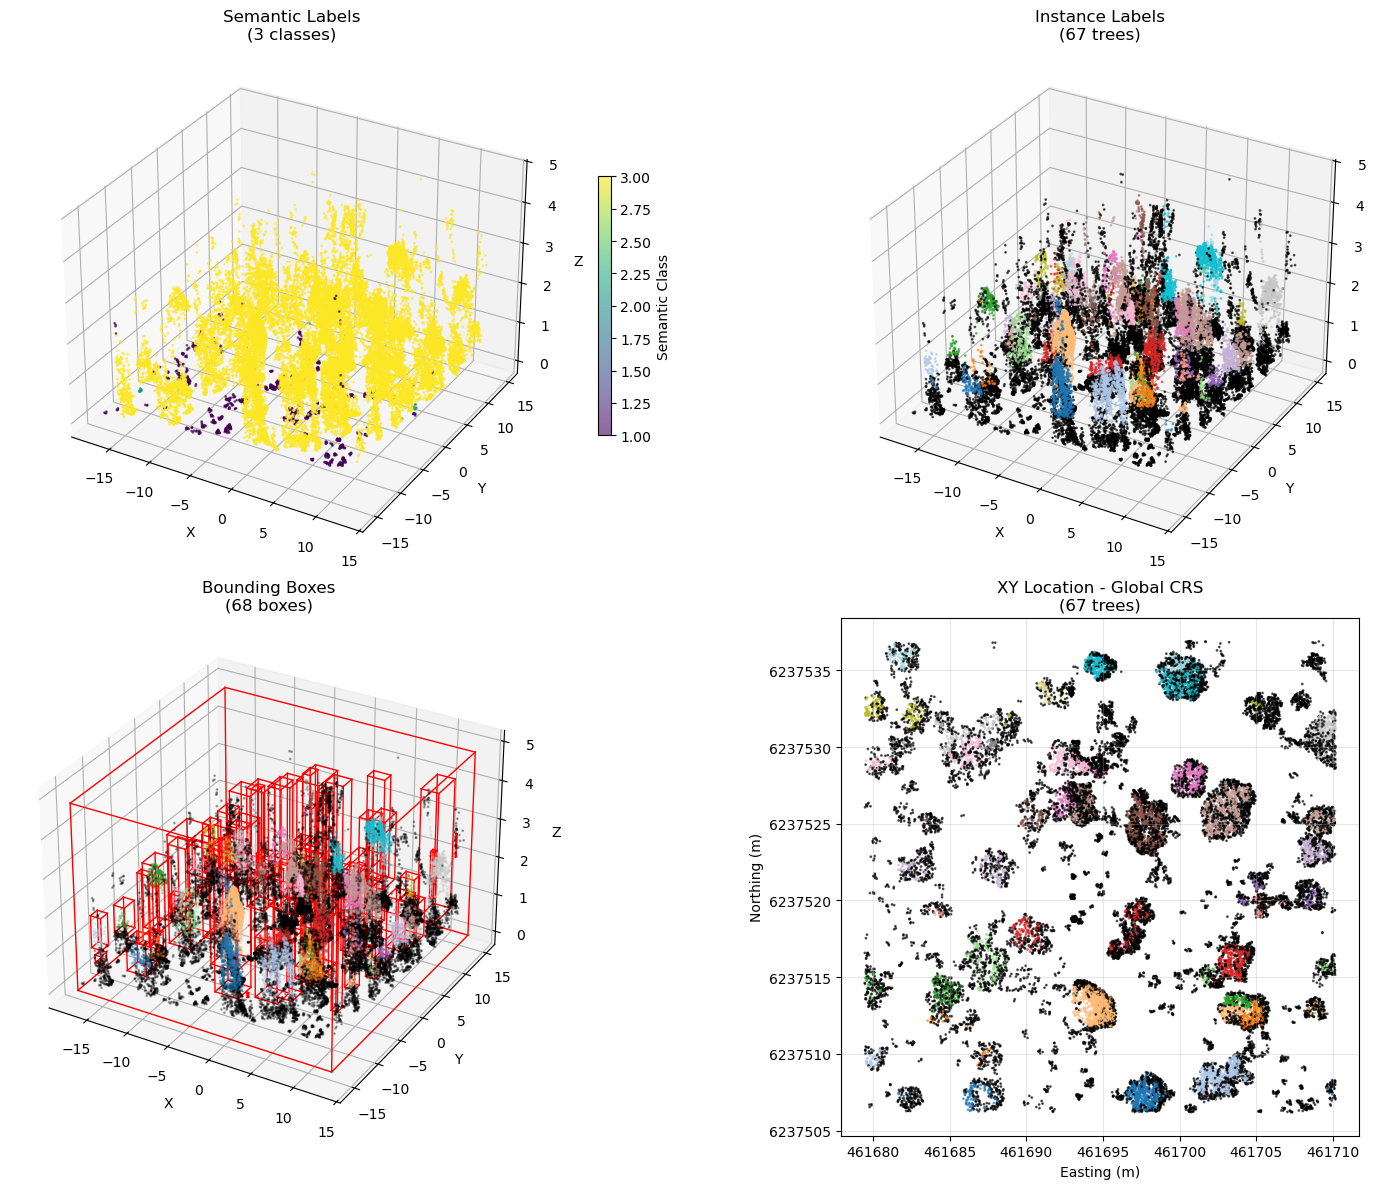


📊 Instance Statistics:
  Tree 1: 971 points
  Tree 2: 5,687 points
  Tree 3: 76 points
  Tree 4: 125 points
  Tree 5: 3,305 points
  Tree 6: 2,358 points
  Tree 7: 483 points
  Tree 8: 112 points
  Tree 9: 1,918 points
  Tree 10: 156 points
  Tree 11: 54 points
  Tree 12: 1,500 points
  Tree 13: 12,469 points
  Tree 14: 304 points
  Tree 15: 1,405 points
  Tree 16: 1,569 points
  Tree 17: 279 points
  Tree 18: 1,590 points
  Tree 19: 415 points
  Tree 20: 354 points
  Tree 21: 4,075 points
  Tree 22: 1,030 points
  Tree 23: 1,147 points
  Tree 24: 1,179 points
  Tree 25: 161 points
  Tree 26: 484 points
  Tree 27: 68 points
  Tree 28: 717 points
  Tree 29: 280 points
  Tree 30: 388 points
  Tree 31: 869 points
  Tree 32: 518 points
  Tree 33: 2,180 points
  Tree 34: 7,004 points
  Tree 35: 59 points
  Tree 36: 1,193 points
  Tree 37: 666 points
  Tree 38: 7,160 points
  Tree 39: 1,242 points
  Tree 40: 5,033 points
  Tree 41: 1,289 points
  Tree 43: 3,384 points
  Tree 44: 304 points


In [8]:
# Visualize saved NPY files
sample_name = "znorm_3Dlabels_106"  # Change to visualize different file
sample_prefix = OUTPUT_NPY_DIR / sample_name

# Load data
vertices = np.load(str(sample_prefix.parent / f"{sample_name}_vert.npy"))
offsets = np.load(str(sample_prefix.parent / f"{sample_name}_offsets.npy"))
sem_labels = np.load(str(sample_prefix.parent / f"{sample_name}_sem_label.npy"))
ins_labels = np.load(str(sample_prefix.parent / f"{sample_name}_ins_label.npy"))
bboxes = np.load(str(sample_prefix.parent / f"{sample_name}_unaligned_bbox.npy"))

# Calculate global coordinates
vertices_global = vertices + offsets

print(f"Visualizing: {sample_name}")
print(f"Points: {vertices.shape[0]:,}, Instances: {len(np.unique(ins_labels[ins_labels > 0]))}")
print(f"Local XY: X[{vertices[:, 0].min():.2f}, {vertices[:, 0].max():.2f}], Y[{vertices[:, 1].min():.2f}, {vertices[:, 1].max():.2f}]")
print(f"Global XY (CRS): X[{vertices_global[:, 0].min():.2f}, {vertices_global[:, 0].max():.2f}], Y[{vertices_global[:, 1].min():.2f}, {vertices_global[:, 1].max():.2f}]")
print(f"Offset: {offsets}\n")

# Create figure with subplots (2x2 grid)
fig = plt.figure(figsize=(18, 12))

# Plot 1: Colored by Semantic Labels
ax1 = fig.add_subplot(221, projection='3d')
scatter1 = ax1.scatter(vertices[::10, 0], vertices[::10, 1], vertices[::10, 2], 
                       c=sem_labels[::10], cmap='viridis', s=1, alpha=0.6)
ax1.set_title(f'Semantic Labels\n({len(np.unique(sem_labels))} classes)', fontsize=12)
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.set_zlabel('Z')
plt.colorbar(scatter1, ax=ax1, label='Semantic Class', shrink=0.5)

# Plot 2: Colored by Instance Labels
ax2 = fig.add_subplot(222, projection='3d')
# Use a colormap with distinct colors for each instance
unique_instances = np.unique(ins_labels[ins_labels > 0])
colors = plt.cm.tab20(np.linspace(0, 1, len(unique_instances)))
instance_colors = np.zeros((len(ins_labels), 3))
for i, inst_id in enumerate(unique_instances):
    mask = ins_labels == inst_id
    instance_colors[mask] = colors[i % len(colors)][:3]

scatter2 = ax2.scatter(vertices[::10, 0], vertices[::10, 1], vertices[::10, 2], 
                       c=instance_colors[::10], s=1, alpha=0.6)
ax2.set_title(f'Instance Labels\n({len(unique_instances)} trees)', fontsize=12)
ax2.set_xlabel('X')
ax2.set_ylabel('Y')
ax2.set_zlabel('Z')

# Plot 3: Point Cloud with Bounding Boxes
ax3 = fig.add_subplot(223, projection='3d')
ax3.scatter(vertices[::10, 0], vertices[::10, 1], vertices[::10, 2], 
           c=instance_colors[::10], s=1, alpha=0.3)

# Draw bounding boxes
for bbox in bboxes:
    cx, cy, cz, dx, dy, dz, class_id = bbox
    # Create box corners
    x = [cx - dx/2, cx + dx/2]
    y = [cy - dy/2, cy + dy/2]
    z = [cz - dz/2, cz + dz/2]
    
    # Draw box edges
    for xi in x:
        for yi in y:
            ax3.plot([xi, xi], [yi, yi], [z[0], z[1]], 'r-', linewidth=1)
    for xi in x:
        for zi in z:
            ax3.plot([xi, xi], [y[0], y[1]], [zi, zi], 'r-', linewidth=1)
    for yi in y:
        for zi in z:
            ax3.plot([x[0], x[1]], [yi, yi], [zi, zi], 'r-', linewidth=1)

ax3.set_title(f'Bounding Boxes\n({bboxes.shape[0]} boxes)', fontsize=12)
ax3.set_xlabel('X')
ax3.set_ylabel('Y')
ax3.set_zlabel('Z')

# Plot 4: XY Location (Top-down view) - Global CRS Coordinates
ax4 = fig.add_subplot(224)
scatter4 = ax4.scatter(vertices_global[::10, 0], vertices_global[::10, 1], 
                       c=instance_colors[::10], s=1, alpha=0.6)
ax4.set_title(f'XY Location - Global CRS\n({len(unique_instances)} trees)', fontsize=12)
ax4.set_xlabel('Easting (m)')
ax4.set_ylabel('Northing (m)')
ax4.grid(True, alpha=0.3)
ax4.set_aspect('equal', adjustable='box')
# Format axis labels to show full coordinate values
ax4.ticklabel_format(style='plain', useOffset=False)

plt.tight_layout()
plt.show()

# Print instance statistics
print("\n📊 Instance Statistics:")
unique, counts = np.unique(ins_labels[ins_labels > 0], return_counts=True)
for inst_id, count in zip(unique, counts):
    print(f"  Tree {inst_id}: {count:,} points")
    
# Print bounding box statistics
print(f"\n📦 Bounding Box Statistics:")
print(f"  Average size: ({bboxes[:, 3].mean():.2f}, {bboxes[:, 4].mean():.2f}, {bboxes[:, 5].mean():.2f})")
print(f"  Max size: ({bboxes[:, 3].max():.2f}, {bboxes[:, 4].max():.2f}, {bboxes[:, 5].max():.2f})")
print(f"  Min size: ({bboxes[:, 3].min():.2f}, {bboxes[:, 4].min():.2f}, {bboxes[:, 5].min():.2f})")

## Convert NPY Files Back to LAS Format

Convert ForestFormer NPY outputs back to LAS for visualization and validation.

In [11]:
# Output directory for reconstructed LAS files
OUT_LAS_DIR = Path("/data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_las_forestformer/")
OUT_LAS_DIR.mkdir(parents=True, exist_ok=True)

print(f"📂 Output LAS directory: {OUT_LAS_DIR}")

📂 Output LAS directory: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_las_forestformer


In [12]:
def npy_to_las(npy_prefix, out_las_path, original_las_path=None):
    """Convert ForestFormer NPY files back to LAS format with original CRS.
    
    Args:
        npy_prefix: Path prefix for NPY files (e.g., /path/to/scan_name)
        out_las_path: Output LAS path
        original_las_path: Optional path to original LAS to preserve CRS and header
    """
    npy_prefix = Path(npy_prefix)
    out_las_path = Path(out_las_path)
    
    print(f"Converting {npy_prefix.name} → {out_las_path.name}")
    
    # Load NPY data from separate files
    vertices = np.load(str(npy_prefix.parent / f"{npy_prefix.name}_vert.npy"))
    offsets = np.load(str(npy_prefix.parent / f"{npy_prefix.name}_offsets.npy"))
    sem_labels = np.load(str(npy_prefix.parent / f"{npy_prefix.name}_sem_label.npy"))
    ins_labels = np.load(str(npy_prefix.parent / f"{npy_prefix.name}_ins_label.npy"))

    
    print(f"  Loaded {len(vertices):,} points")
    print(f"  Local coords range: [{vertices.min(axis=0)}, {vertices.max(axis=0)}]")
    print(f"  Offset (global origin): {offsets}")
    
    # Load CRS sidecar if available
    crs_sidecar = npy_prefix.parent / f"{npy_prefix.name}_crs.npz"
    crs_info = None
    saved_original_las_path = None
    
    if crs_sidecar.exists():
        crs_data = np.load(str(crs_sidecar), allow_pickle=True)
        crs_wkt = None
        if 'crs_wkt' in crs_data and len(crs_data['crs_wkt']) > 0:
            crs_wkt = str(crs_data['crs_wkt'][0])
        
        crs_info = {
            'crs_wkt': crs_wkt,
            'has_vlrs': bool(crs_data['has_vlrs']) if 'has_vlrs' in crs_data else False,
            'header_offset': crs_data['header_offset'] if 'header_offset' in crs_data else None,
            'header_scale': crs_data['header_scale'] if 'header_scale' in crs_data else None,
        }
        print(f"  ✓ Loaded CRS sidecar")
    
    # Check for original LAS path reference (for VLR copying)
    orig_las_ref = npy_prefix.parent / f"{npy_prefix.name}_original_las_path.txt"
    if orig_las_ref.exists():
        try:
            with open(str(orig_las_ref), 'r') as f:
                saved_original_las_path = Path(f.read().strip())
            if saved_original_las_path.exists():
                print(f"  ✓ Found original LAS reference: {saved_original_las_path.name}")
        except Exception as e:
            print(f"  ⚠️ Could not read original LAS reference: {e}")
    
    # Try to get original LAS for header and CRS (prefer saved reference, then parameter)
    use_original_header = False
    original_las = None
    
    # Prioritize saved original LAS path reference
    las_to_use = saved_original_las_path if saved_original_las_path and saved_original_las_path.exists() else original_las_path
    
    # Reconstruct absolute coordinates first (needed for fallback offset calculation)
    xyz_abs = vertices + offsets
    
    if las_to_use and Path(las_to_use).exists():
        original_las = laspy.read(str(las_to_use))
        header_offset = np.array(original_las.header.offsets, dtype=np.float64)
        header_scale = np.array(original_las.header.scales, dtype=np.float64)
        print(f"  Using original header from {Path(las_to_use).name}")
        use_original_header = True
    elif crs_info and crs_info['header_offset'] is not None:
        header_offset = crs_info['header_offset']
        header_scale = crs_info['header_scale']
        print(f"  Using saved header: offset={header_offset}, scale={header_scale}")
    else:
        # Fallback: compute from data
        header_offset = xyz_abs.min(axis=0)
        header_scale = np.array([0.001, 0.001, 0.001])
        print(f"  ⚠️ No original header found, using computed offset")
    
    print(f"  Global coords range: [{xyz_abs.min(axis=0)}, {xyz_abs.max(axis=0)}]")
    
    # Create LAS header with offset and scale
    header = laspy.LasHeader(version="1.4", point_format=6)
    header.offsets = header_offset
    header.scales = header_scale
    
    # Copy CRS from original if available (VLRs are the most reliable method)
    if use_original_header and original_las:
        # Copy VLRs (Variable Length Records) which contain CRS info
        for vlr in original_las.header.vlrs:
            header.vlrs.append(vlr)
        print(f"  ✅ Copied {len(original_las.header.vlrs)} VLRs (including CRS)")
    elif crs_info and crs_info.get('crs_wkt'):
        # Fallback: try to reconstruct CRS from WKT string
        try:
            from pyproj import CRS
            crs_obj = CRS.from_wkt(crs_info['crs_wkt'])
            header.add_crs(crs_obj)
            print(f"  ✅ Attached CRS from WKT sidecar")
        except Exception as e:
            print(f"  ⚠️ Could not attach CRS from WKT: {e}")
            print(f"     (This is OK if original LAS has VLRs that were copied)")
    
    # Add extra dimensions
    # Note: Using 'intensity_norm' since 'intensity' conflicts with built-in LAS field
    intensity_extra_bytes = laspy.ExtraBytesParams(name="intensity_norm", type="f4", description="Intensity from PLY (float32)")
    header.add_extra_dim(intensity_extra_bytes)
    
    z_norm_extra_bytes = laspy.ExtraBytesParams(name="z_norm", type="f4", description="Normalized height (m)")
    header.add_extra_dim(z_norm_extra_bytes)
    
    # Create LAS data
    las = laspy.LasData(header)
    
    # Set coordinates (will use header offset/scale)
    las.x = xyz_abs[:, 0]
    las.y = xyz_abs[:, 1]
    las.z = xyz_abs[:, 2]
    
    # Set classification to 0 (unclassified) as default
    las.classification = np.zeros(len(vertices), dtype=np.uint8)
    
    # Load intensity - first try saved intensity file, then fall back to PLY
    intensity_file = npy_prefix.parent / f"{npy_prefix.name}_intensity.npy"
    
    if intensity_file.exists():
        try:
            intensity_values = np.load(str(intensity_file))
            if len(intensity_values) == len(vertices):
                # Set intensity as float32 in extra dimension (keep original values, no scaling)
                las['intensity_norm'] = intensity_values.astype(np.float32)
                print(f"  ✓ Loaded intensity from saved file: range [{intensity_values.min():.2f}, {intensity_values.max():.2f}]")
            else:
                print(f"  ⚠️ Intensity file point count mismatch, using default")
                las['intensity_norm'] = np.full(len(vertices), 100.0, dtype=np.float32)
        except Exception as e:
            las['intensity_norm'] = np.full(len(vertices), 100.0, dtype=np.float32)
    else:
        # Fallback: try to load from original PLY file
        try:
            ply_path = Path(str(npy_prefix.parent).replace('forestformer3d_npz', 'forestformer3d_ply')) / f"{npy_prefix.name}.ply"
            
            if ply_path.exists():
                from pyntcloud import PyntCloud
                ply_cloud = PyntCloud.from_file(str(ply_path))
                
                if 'intensity' in ply_cloud.points.columns:
                    ply_intensity = ply_cloud.points['intensity'].values
                    
                    if len(ply_intensity) == len(vertices):
                        # Keep original float32 values (no scaling)
                        las['intensity_norm'] = ply_intensity.astype(np.float32)
                        print(f"  ✓ Loaded intensity from PLY: range [{ply_intensity.min():.2f}, {ply_intensity.max():.2f}]")
                    else:
                        print(f"  ⚠️ PLY point count mismatch ({len(ply_intensity)} vs {len(vertices)}), using default")
                        las['intensity_norm'] = np.full(len(vertices), 100.0, dtype=np.float32)
                else:
                    print(f"  ⚠️ No intensity column in PLY, using default")
                    las['intensity_norm'] = np.full(len(vertices), 100.0, dtype=np.float32)
            else:
                print(f"  ⚠️ PLY file not found, using default intensity")
                las['intensity_norm'] = np.full(len(vertices), 100.0, dtype=np.float32)
        except Exception as e:
            print(f"  ⚠️ Could not load intensity from PLY: {e}, using default")
            las['intensity_norm'] = np.full(len(vertices), 100.0, dtype=np.float32)
    
    # Load z_norm (normalized height)
    z_norm_file = npy_prefix.parent / f"{npy_prefix.name}_z_norm.npy"
    if z_norm_file.exists():
        try:
            z_norm_values = np.load(str(z_norm_file))
            if len(z_norm_values) == len(vertices):
                las['z_norm'] = z_norm_values.astype(np.float32)
                print(f"  ✓ Loaded z_norm: range [{z_norm_values.min():.2f}, {z_norm_values.max():.2f}] m")
            else:
                print(f"  ⚠️ z_norm file point count mismatch, using computed values")
                las['z_norm'] = (vertices[:, 2] - vertices[:, 2].min()).astype(np.float32)
        except Exception as e:
            print(f"  ⚠️ Could not load z_norm: {e}, computing from vertices")
            las['z_norm'] = (vertices[:, 2] - vertices[:, 2].min()).astype(np.float32)
    else:
        # Compute z_norm if not saved
        las['z_norm'] = (vertices[:, 2] - vertices[:, 2].min()).astype(np.float32)
        print(f"  ℹ️ Computed z_norm from vertices: range [{las['z_norm'].min():.2f}, {las['z_norm'].max():.2f}] m")
    
    # Add extra dimensions for semantic and instance labels (matching PLY naming convention)
    las.add_extra_dim(laspy.ExtraBytesParams(name="semantic_seg", type=np.int32))
    las.add_extra_dim(laspy.ExtraBytesParams(name="treeID", type=np.int32))
    
    las["semantic_seg"] = sem_labels.astype(np.int32)
    las["treeID"] = ins_labels.astype(np.int32)
    
    # Write LAS file
    las.write(str(out_las_path))
    print(f"✅ Saved: {out_las_path}")
    return out_las_path

def batch_npy_to_las(npy_folder, output_las_folder, original_las_folder=None, max_files=None):
    """Batch convert ForestFormer NPY files to LAS format.
    
    Args:
        npy_folder: Folder containing NPY files
        output_las_folder: Output folder for LAS files
        original_las_folder: Optional folder with original LAS files for CRS
        max_files: Optional limit on number of files to convert
    """
    npy_folder = Path(npy_folder)
    output_las_folder = Path(output_las_folder)
    output_las_folder.mkdir(parents=True, exist_ok=True)
    
    # Find all _vert.npy files (one per scan)
    vert_files = sorted(npy_folder.glob("*_vert.npy"))
    
    if max_files:
        vert_files = vert_files[:max_files]
    
    print(f"\n🔄 Converting {len(vert_files)} NPY sets to LAS format...")
    
    for i, vert_file in enumerate(vert_files, 1):
        # Extract scan name (remove _vert.npy suffix)
        scan_name = vert_file.stem.replace("_vert", "")
        
        print(f"\n[{i}/{len(vert_files)}] Processing: {scan_name}")
        
        # Build paths
        npy_prefix = npy_folder / scan_name
        out_las = output_las_folder / f"{scan_name}_from_npy.las"
        
        # Try to find original LAS
        orig_las = None
        if original_las_folder:
            orig_las = guess_original_las(scan_name)
            if orig_las and not orig_las.exists():
                orig_las = None
        
        # Convert
        try:
            npy_to_las(npy_prefix, out_las, original_las_path=orig_las)
        except Exception as e:
            print(f"  ✗ Failed: {e}")
            import traceback
            traceback.print_exc()
    
    print(f"\n✅ Batch conversion complete!")

In [ ]:
# Convert one sample NPY to LAS
sample_files = sorted(OUTPUT_PLY_DIR.glob("*_vert.npy"))

if sample_files:
    sample_vert = sample_files[0]
    scan_name = sample_vert.stem.replace("_vert", "")
    
    print(f"Converting sample: {scan_name}\n")
    
    npy_prefix = OUTPUT_PLY_DIR / scan_name
    out_las = OUT_LAS_DIR / f"{scan_name}_from_npy.las"
    orig_las = guess_original_las(scan_name)
    
    print(f"NPY prefix: {npy_prefix}")
    print(f"Output LAS: {out_las}")
    print(f"Original LAS: {orig_las if orig_las and orig_las.exists() else 'Not found'}\n")
    
    npy_to_las(npy_prefix, out_las, original_las_path=orig_las if orig_las and orig_las.exists() else None)
else:
    print("❌ No NPY files found. Run the export cell first.")

Converting sample: znorm_3Dlabels_106

NPY prefix: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/forestformer3d_npz/znorm_3Dlabels_106
Output LAS: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_las_forestformer/znorm_3Dlabels_106_from_npy.las
Original LAS: /data/calperumResearch/site1_1_DD0001/lidar/clipped/3d_structure_mask_malleid/znorm_3Dlabels_106.las

Converting znorm_3Dlabels_106 → znorm_3Dlabels_106_from_npy.las
  Loaded 265,746 points
  Local coords range: [[-17.528542 -15.812152   0.      ], [13.171459 14.887849  4.92    ]]
  Offset (global origin): [4.61696999e+05 6.23752201e+06 5.78300000e+01]
  ✓ Loaded CRS sidecar
  ✓ Found original LAS reference: znorm_3Dlabels_106.las
  Using original header from znorm_3Dlabels_106.las


  Global coords range: [[4.6167947e+05 6.2375062e+06 5.7830000e+01], [4.61710170e+05 6.23753690e+06 6.27500001e+01]]
  ✅ Copied 3 VLRs (including CRS)
  ✓ Loaded intensity from saved file: range [0.00, 0.42]
  ✓ Loaded z_norm: range [0.00, 4.92] m
✅ Saved: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_las_forestformer/znorm_3Dlabels_106_from_npy.las


In [14]:
# Batch convert all NPY files to LAS (uncomment to run)
batch_npy_to_las(
    npy_folder=OUTPUT_PLY_DIR,
    output_las_folder=OUT_LAS_DIR,
    original_las_folder=INPUT_DIR,
    max_files=None  # Set to limit number of files
)


🔄 Converting 15 NPY sets to LAS format...

[1/15] Processing: znorm_3Dlabels_106
Converting znorm_3Dlabels_106 → znorm_3Dlabels_106_from_npy.las
  Loaded 265,746 points
  Local coords range: [[-17.528542 -15.812152   0.      ], [13.171459 14.887849  4.92    ]]
  Offset (global origin): [4.61696999e+05 6.23752201e+06 5.78300000e+01]
  ✓ Loaded CRS sidecar
  ✓ Found original LAS reference: znorm_3Dlabels_106.las
  Using original header from znorm_3Dlabels_106.las
  Global coords range: [[4.6167947e+05 6.2375062e+06 5.7830000e+01], [4.61710170e+05 6.23753690e+06 6.27500001e+01]]
  ✅ Copied 3 VLRs (including CRS)
  ✓ Loaded intensity from saved file: range [0.00, 0.42]
  ✓ Loaded z_norm: range [0.00, 4.92] m


✅ Saved: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_las_forestformer/znorm_3Dlabels_106_from_npy.las

[2/15] Processing: znorm_3Dlabels_109
Converting znorm_3Dlabels_109 → znorm_3Dlabels_109_from_npy.las
  Loaded 394,473 points
  Local coords range: [[-15.158568 -15.177109   0.      ], [15.551431 15.522892  5.64    ]]
  Offset (global origin): [4.61786679e+05 6.23752132e+06 5.94300000e+01]
  ✓ Loaded CRS sidecar
  ✓ Found original LAS reference: znorm_3Dlabels_109.las
  Using original header from znorm_3Dlabels_109.las
  Global coords range: [[4.61771520e+05 6.23750614e+06 5.94300000e+01], [4.61802230e+05 6.23753684e+06 6.50699999e+01]]
  ✅ Copied 3 VLRs (including CRS)
  ✓ Loaded intensity from saved file: range [0.00, 0.41]
  ✓ Loaded z_norm: range [0.00, 5.64] m
✅ Saved: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_las_forestformer/znorm_3Dlabels_109_from_npy.las

[3/15] Processing: znorm_3Dlabels_113
Converting z